In [6]:
import wandb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

wandb.login()

True

In [7]:
project_path = "reward-shaping/mountaincar-reward-shaping-v1"

api = wandb.Api()
runs = api.runs(project_path)

print(f"Found {len(runs)} runs in {project_path}")

Found 9 runs in reward-shaping/mountaincar-reward-shaping-v1


In [10]:
import ast
all_data = []

for run in runs:
    history = run.history()
    cfg = run.config
    
    # If config is a string, parse it to a dict
    if isinstance(cfg, str):
        try:
            cfg = ast.literal_eval(cfg)
        except Exception:
            cfg = {}

    # Add identifying info
    history['run_name'] = run.name
    history['algorithm'] = cfg.get('algorithm', None)
    history['reward_type'] = cfg.get('reward_type', None)
    history['id'] = run.id

    all_data.append(history)

df = pd.concat(all_data, ignore_index=True)

print(f"Loaded {len(df)} rows from {len(runs)} runs")
import re

# Extract algorithm and reward_type from run_name, assuming names like 'ppo_none', 'dqn_potential', etc.
def parse_run_name(name):
    match = re.match(r"(\w+)_([\w]+)", name)
    if match:
        return match.group(1), match.group(2)
    return None, None

df["algorithm"], df["reward_type"] = zip(*df["run_name"].map(parse_run_name))

df[["run_name", "algorithm", "reward_type"]].drop_duplicates().sort_values("run_name")
df.head()

Loaded 4500 rows from 9 runs


,explained_variance,_timestamp,avg_shaping_reward,_runtime,entropy_loss,episode_length,episode_reward,_step,value_loss,training_videos,...,reward_type,id,total_reward,shaping_reward,env_reward,visited_best_q,epsilon,mean_q,avg_env_reward,max_q
0,NaN,1.762522e+09,0.0,3.645187,NaN,200.0,-200.0,0,NaN,None,...,none,my5ojx9t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1.762522e+09,0.0,3.834347,NaN,200.0,-200.0,1,NaN,None,...,none,my5ojx9t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,1.762522e+09,0.0,4.697960,NaN,200.0,-200.0,7,NaN,None,...,none,my5ojx9t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,1.762522e+09,0.0,4.842495,NaN,200.0,-200.0,8,NaN,None,...,none,my5ojx9t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,1.762522e+09,0.0,4.984370,NaN,200.0,-200.0,9,NaN,None,...,none,my5ojx9t,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
df.describe()

,explained_variance,_timestamp,avg_shaping_reward,_runtime,entropy_loss,episode_length,episode_reward,_step,value_loss,policy_gradient_loss,episode,avg_total_reward,learning_rate,loss,visited_best_q,epsilon,mean_q,avg_env_reward,max_q
count,501.000000,4.500000e+03,2516.000000,4500.000000,501.000000,2516.000000,2516.000000,4500.000000,501.000000,501.000000,2516.000000,2516.000000,1009.000000,1009.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,0.957840,1.762531e+09,-3.524894,171.920627,-0.176386,170.570350,-174.095004,47388.994444,0.014769,-0.001620,870.410175,-117.298343,0.000652,1.390946,-11.633290,0.123657,-21.931937,-190.825333,-0.000532
std,0.101757,6.934636e+03,7.746373,166.470089,0.237283,35.651207,38.527695,64007.223965,0.023208,0.002157,538.462220,97.666411,0.000350,3.228090,16.757577,0.210415,10.144528,16.185141,0.015875
min,0.015609,1.762522e+09,-23.431753,1.501212,-1.095154,83.000000,-223.431641,0.000000,0.002498,-0.010864,0.000000,-223.431641,0.000300,-0.041950,-91.457659,0.020000,-39.081066,-200.000000,-0.598502
25%,0.968376,1.762524e+09,0.000000,26.784477,-0.136131,148.000000,-200.000000,757.000000,0.006503,-0.002098,404.000000,-200.000000,0.000300,0.000306,-14.025911,0.020000,-30.787656,-200.000000,0.000000
50%,0.979751,1.762531e+09,0.000000,124.849534,-0.075153,189.500000,-192.742119,1586.000000,0.012299,-0.000847,847.000000,-176.198532,0.001000,0.009212,-4.866821,0.020000,-23.404283,-200.000000,0.000000
75%,0.986002,1.762540e+09,0.000000,276.339018,-0.062733,200.000000,-148.000000,94908.000000,0.020107,-0.000316,1291.000000,0.000000,0.001000,1.313068,-1.641165,0.101965,-12.400632,-185.000000,0.000000
max,0.994791,1.762540e+09,2.073237,599.188113,-0.048806,200.000000,-83.000000,202160.000000,0.360226,0.001645,1995.000000,0.000000,0.001000,29.029598,0.000000,0.995000,-0.722854,-108.000000,0.000000


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   explained_variance    501 non-null    float64
 1   _timestamp            4500 non-null   float64
 2   avg_shaping_reward    2516 non-null   float64
 3   _runtime              4500 non-null   float64
 4   entropy_loss          501 non-null    float64
 5   episode_length        2516 non-null   float64
 6   episode_reward        2516 non-null   float64
 7   _step                 4500 non-null   int64  
 8   value_loss            501 non-null    float64
 9   training_videos       0 non-null      object 
 10  policy_gradient_loss  501 non-null    float64
 11  episode               2516 non-null   float64
 12  avg_total_reward      2516 non-null   float64
 13  learning_rate         1009 non-null   float64
 14  loss                  1009 non-null   float64
 15  run_name             

C:\Users\Alex\AppData\Local\Temp\ipykernel_136416\3070308031.py:8: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.lineplot(


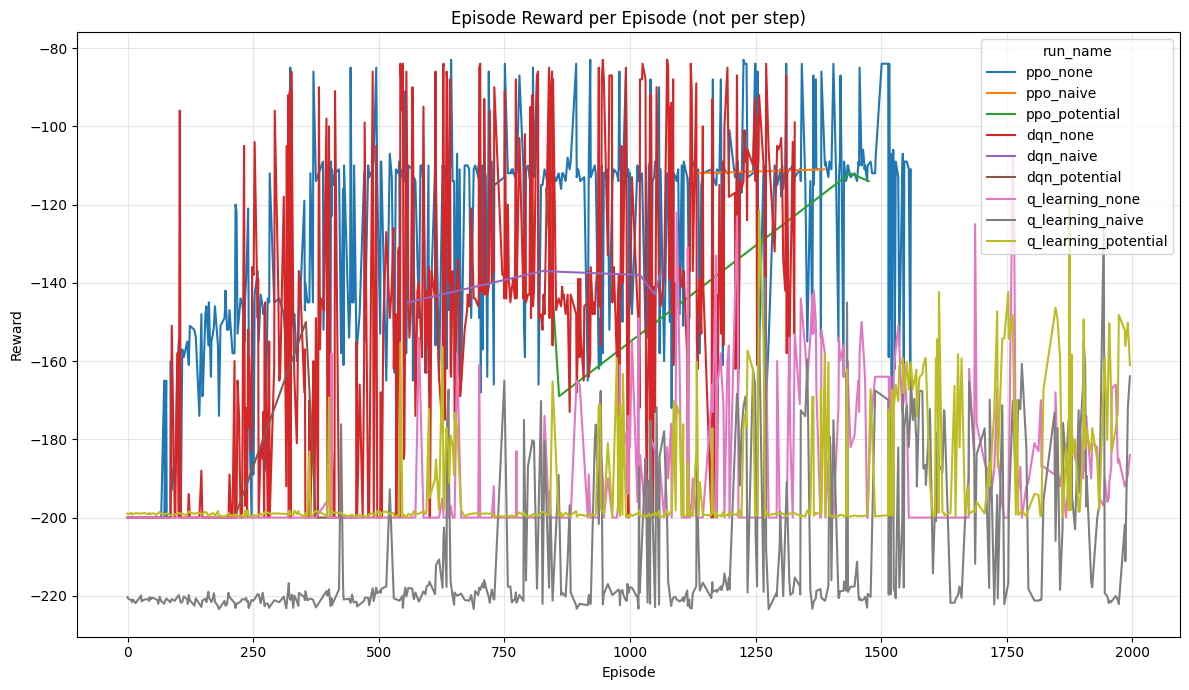

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Only keep rows where episode data is available (not NaN)
episode_df = df.dropna(subset=["episode", "episode_reward"])

plt.figure(figsize=(12,7))
sns.lineplot(
    data=episode_df,
    x="episode", y="episode_reward",
    hue="run_name",
    estimator="mean", ci="sd"
)
plt.title("Episode Reward per Episode (not per step)")
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

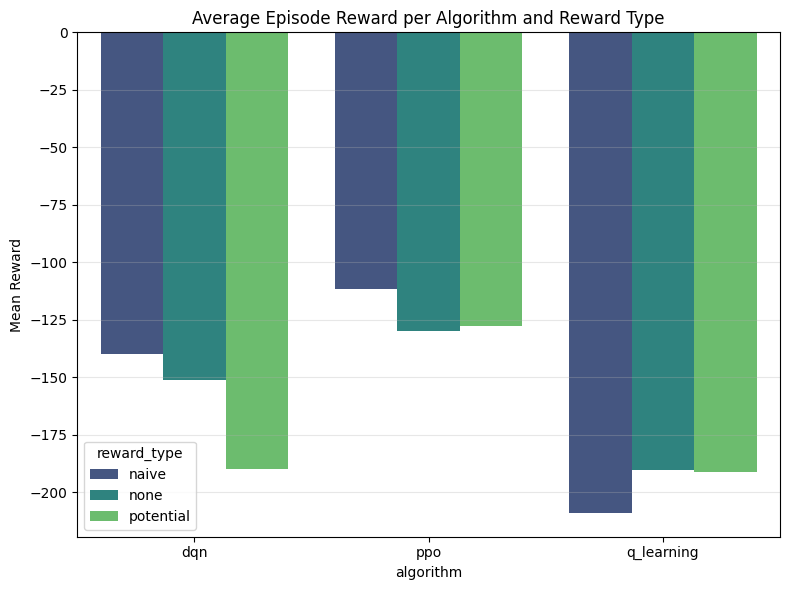

In [ ]:
avg_rewards = (
    df.groupby(["algorithm", "reward_type"])["episode_reward"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(8,6))
sns.barplot(
    data=avg_rewards,
    x="algorithm", y="episode_reward", 
    hue="reward_type", palette="viridis"
)
plt.title("Average Episode Reward per Algorithm and Reward Type")
plt.ylabel("Mean Reward")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


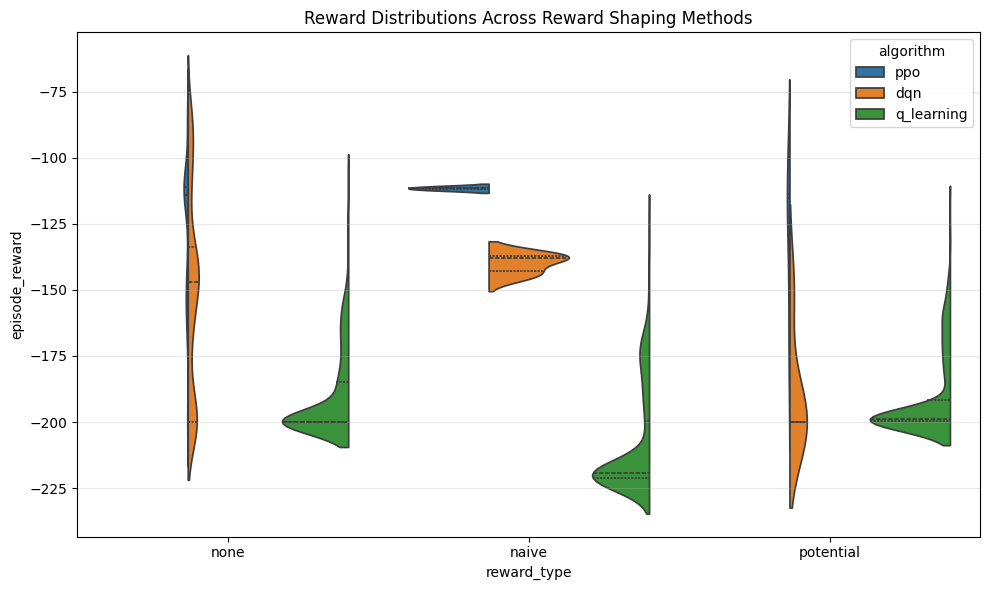

In [18]:
plt.figure(figsize=(10,6))
sns.violinplot(
    data=df,
    x="reward_type", y="episode_reward",
    hue="algorithm",
    split=True, inner="quartile"
)
plt.title("Reward Distributions Across Reward Shaping Methods")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

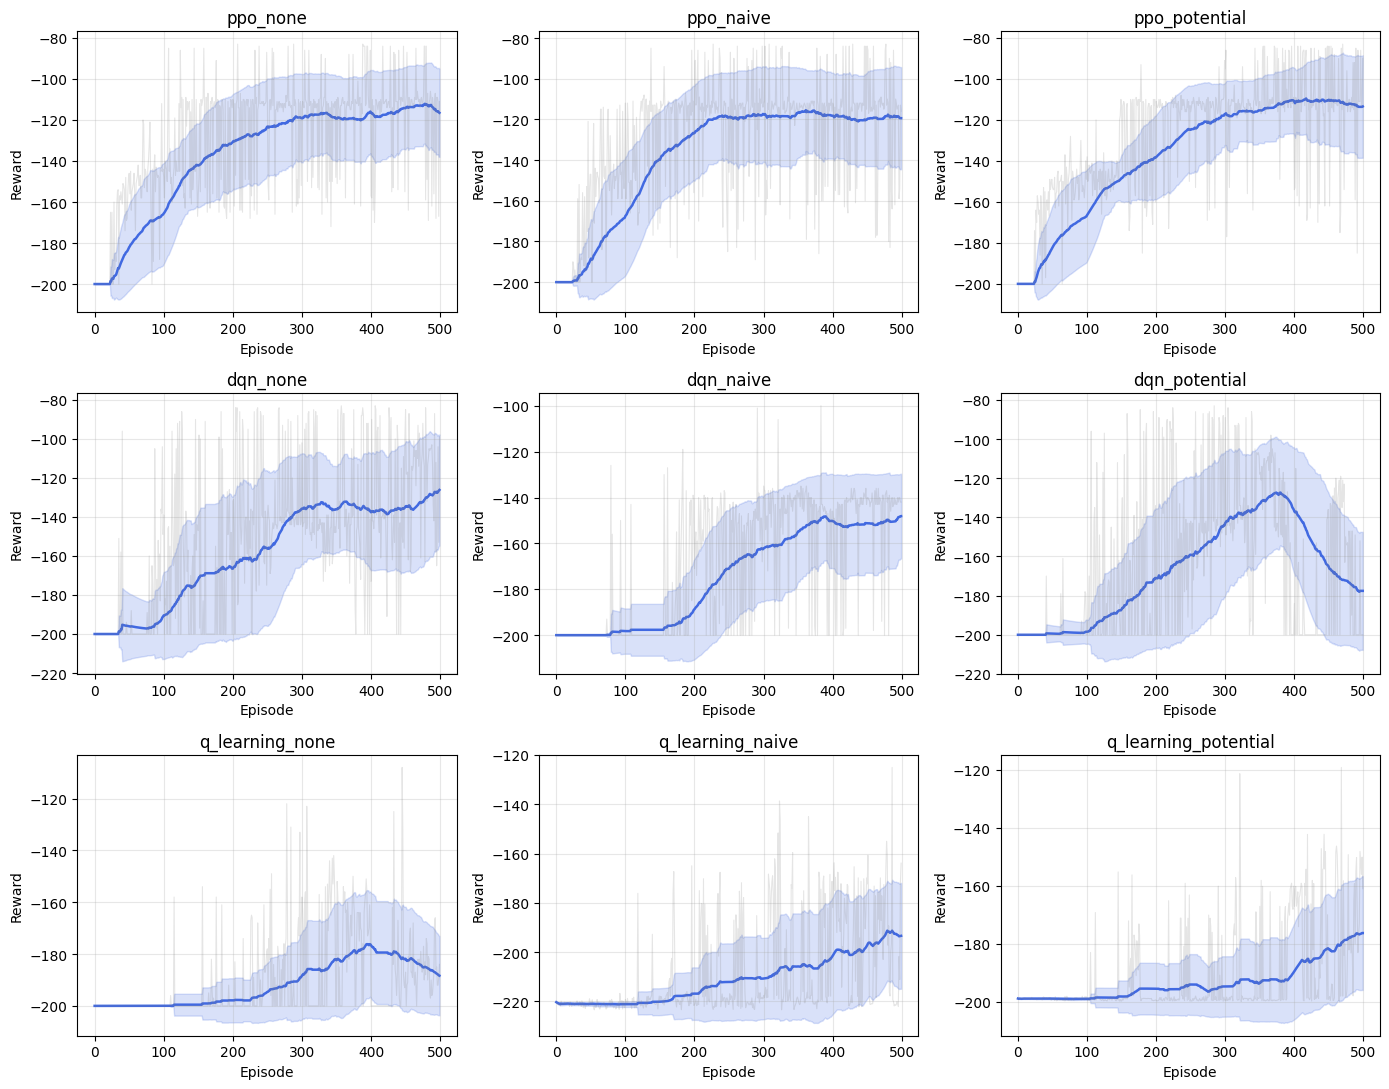

In [26]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()  # make it easier to index 0–8

window_size = 100  # adjust for smoother or more detailed curves

for i, run in enumerate(runs[:9]):  # limit to 9 runs
    ax = axes[i]
    
    # Extract rewards
    history = run.history(keys=["episode_reward"])
    rewards = pd.Series(history["episode_reward"])
    episodes = np.arange(len(rewards))
    
    # Smooth with rolling mean
    smooth = rewards.rolling(window=window_size, min_periods=1).mean()
    std = rewards.rolling(window=window_size, min_periods=1).std()
    
    # Plot smooth line
    ax.plot(episodes, smooth, color="royalblue", linewidth=1.8, label="Smoothed Reward")
    
    # Add shaded area (like background)
    ax.fill_between(episodes, smooth - std, smooth + std, color="royalblue", alpha=0.2)
    
    # Optional: plot raw data (light gray)
    ax.plot(episodes, rewards, color="gray", alpha=0.2, linewidth=0.8, label="Raw Reward")
    
    # Labels and styling
    ax.set_title(run.name)
    ax.set_xlabel("Episode")
    ax.set_ylabel("Reward")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


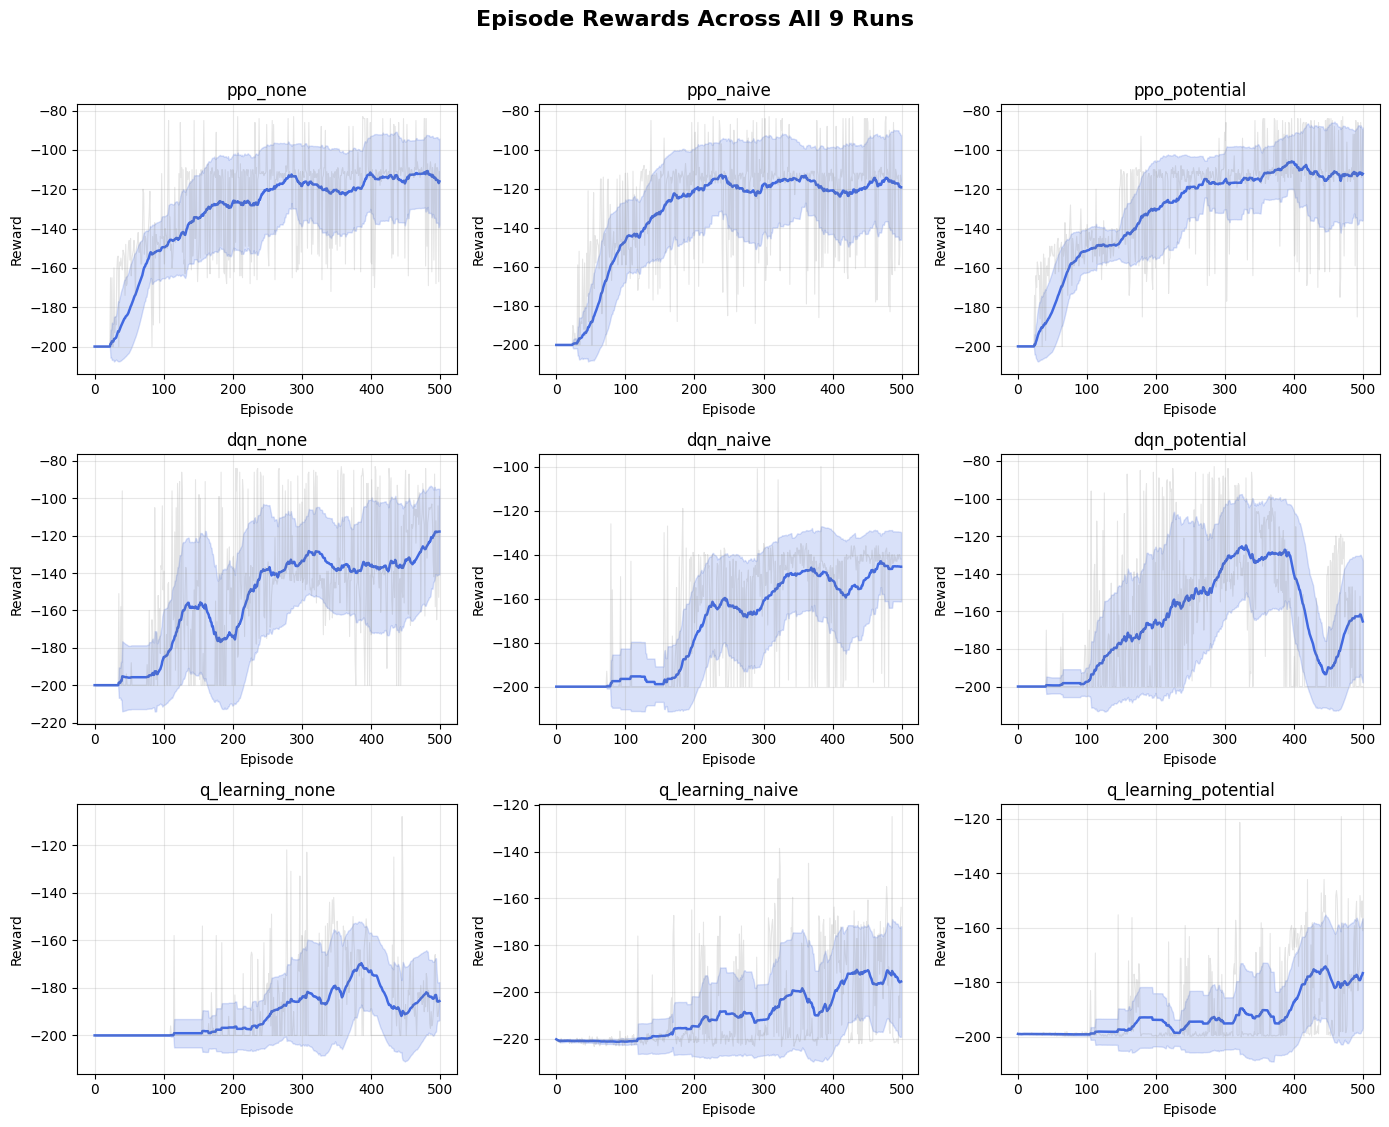

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
axes = axes.flatten()  # make it easier to index 0–8

window_size = 10  # adjust for smoother or more detailed curves

for i, run in enumerate(runs[:9]):  # limit to 9 runs
    ax = axes[i]
    
    # Extract rewards
    history = run.history(keys=["episode_reward"])
    rewards = pd.Series(history["episode_reward"])
    episodes = np.arange(len(rewards))
    
    # Smooth with rolling mean
    smooth = rewards.rolling(window=window_size, min_periods=1).mean()
    std = rewards.rolling(window=window_size, min_periods=1).std()
    
    # Plot smooth line
    ax.plot(episodes, smooth, color="royalblue", linewidth=1.8, label="Smoothed Reward")
    
    # Add shaded area (like background)
    ax.fill_between(episodes, smooth - std, smooth + std, color="royalblue", alpha=0.2)
    
    # Optional: plot raw data (light gray)
    ax.plot(episodes, rewards, color="gray", alpha=0.2, linewidth=0.8, label="Raw Reward")
    
    # Labels and styling
    ax.set_title(run.name)
    ax.set_xlabel("Episode")
    ax.set_ylabel("Reward")
    ax.grid(True, alpha=0.3)

# --- Add a global title ---
fig.suptitle("Episode Rewards Across All 9 Runs", fontsize=16, fontweight="bold", y=1.02)

plt.tight_layout()
plt.show()
